# Améliorer le plan E par recuit simulé sur `2_medium`
Le notebook 09 a construit le plan E (271 511 points) avec des règles gloutonnes guidées par un programme linéaire. Un glouton **ne revient jamais sur ses choix**. Le recuit simulé, lui, part d'une solution et la modifie pas à pas, en acceptant parfois de **perdre un peu** pour sortir d'un optimum local.

Même démarche que dans les notebooks 08 et 09 : on pose le problème, on construit les outils, on fait des essais, on compare, puis on écrit la solution et on la fait vérifier.

**Prérequis** : `datasets/2_medium.json`, `test_solution.py`, et `solutions/2_medium_main.json` (écrit par le notebook 09 ; il est copié dans `2_medium_plan_e.json` à la première exécution). Bibliothèques : `pandas`, `numpy`, `scipy`, `matplotlib`.

## 1. Charger l'instance et le plan E

In [1]:
from pathlib import Path
import sys, json, time, bisect, random, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from scipy.sparse import csr_matrix, hstack, vstack, identity
pd.set_option("display.width", 150)

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT_DIR))
from test_solution import getSolutionScore

DATASET = ROOT_DIR / "datasets" / "2_medium.json"
DATASET_TXT = DATASET.read_text()
instance = json.loads(DATASET_TXT)
energy_cap = instance["energyCap"]

# Ici on travaille avec des dictionnaires plutôt qu'avec pandas : le recuit fait des dizaines de milliers
# de petites modifications, et un accès dictionnaire est bien plus rapide qu'un accès DataFrame.
VALUE  = {m["id"]: m["value"] for m in instance["models"]}
ENERGY = {m["id"]: m["energyCost"] for m in instance["models"]}
NEEDS  = {m["id"]: [(t, b["lowerBound"], b["upperBound"]) for t, b in m["dataRequirements"].items()] for m in instance["models"]}
SIZE   = {d["id"]: d["size"] for d in instance["datasets"]}
TYPE   = {d["id"]: d["dataType"] for d in instance["datasets"]}
COPY   = {d["id"]: d["isCopyrighted"] for d in instance["datasets"]}
IMPOSSIBLE = {m for m, needs in NEEDS.items() if any(lo > hi for _, lo, hi in needs)}
TYPES_OF = {m: {t for t, _, _ in needs} for m, needs in NEEDS.items()}

# Le recuit part toujours du plan E. À la première exécution, on le met de côté dans 2_medium_plan_e.json,
# car la fin du notebook peut remplacer 2_medium_main.json par une solution meilleure.
start_file = ROOT_DIR / "solutions" / "2_medium_plan_e.json"
if not start_file.exists():
    start_file.write_text((ROOT_DIR / "solutions" / "2_medium_main.json").read_text())
plan_e = json.loads(start_file.read_text())
score_e, valid, _ = getSolutionScore(json.dumps(plan_e), DATASET_TXT, show_details=False)
print(f"plan E : score = {score_e} | valide = {valid}")

plan E : score = 271511 | valide = True


## 2. Où est le plafond ?
Dans le notebook 09, la borne du programme linéaire valait 272 634. Elle comptait les 58 modèles « impossibles » à demi-valeur sans payer leurs sources, et on a vu que les sources ne rapportent presque rien. On recalcule donc la borne **sans** ces modèles : c'est l'objectif réaliste du recuit.

In [2]:
def lp_bound(include_impossible):
    ids = sorted(VALUE)
    n = len(ids)
    v = np.array([VALUE[m] for m in ids], float)
    e = np.array([ENERGY[m] for m in ids], float)
    possible = np.array([m not in IMPOSSIBLE for m in ids])
    L = np.zeros((n, 4))                                   # besoin minimal par type (besoins possibles uniquement)
    for i, m in enumerate(ids):
        for t, lo, hi in NEEDS[m]:
            if lo <= hi:
                L[i, "ntic".index(t)] += lo
    half_ok = np.ones(n, bool) if include_impossible else possible
    c = -np.concatenate([v * possible, (v // 2) * half_ok])
    rows, rhs = [np.concatenate([e, e])], [energy_cap]
    for j, t in enumerate("ntic"):
        rows.append(np.concatenate([L[:, j], np.zeros(n)]))
        rhs.append(sum(SIZE[d] for d in SIZE if TYPE[d] == t and COPY[d] == 0))
    A = vstack([csr_matrix(np.array(rows)), hstack([identity(n), identity(n)])])
    res = linprog(c, A_ub=A, b_ub=np.concatenate([rhs, np.ones(n)]), bounds=(0, 1), method="highs")
    return -res.fun

bound_all = lp_bound(include_impossible=True)
bound = lp_bound(include_impossible=False)
print(f"borne du notebook 09 (avec modèles impossibles) : {bound_all:,.0f}")
print(f"borne sans modèles impossibles                 : {bound:,.0f}")
print(f"écart à combler depuis le plan E               : {bound - score_e:,.0f} points")

borne du notebook 09 (avec modèles impossibles) : 272,634
borne sans modèles impossibles                 : 272,301
écart à combler depuis le plan E               : 790 points


**Lecture** : il reste au plus environ 790 points à gagner, soit 0,3 % du score. Le recuit ne peut pas faire de miracle. La question est de savoir **combien de ces 790 points il récupère**.

## 3. Le principe du recuit simulé
C'est l'algorithme de Metropolis de la physique statistique, appliqué à une solution au lieu d'un système de particules :
1. on part d'une solution (ici le plan E) ;
2. on propose une **petite modification** (un « mouvement ») ;
3. on calcule la variation de score $\Delta$ ;
4. si $\Delta \ge 0$, on accepte. Sinon, on accepte quand même avec la probabilité $e^{\Delta / T}$ ;
5. on baisse la température $T$ et on recommence.

À haute température, on accepte facilement des pertes : on **explore**. À basse température, on n'accepte presque plus que des gains : on **affine**. À $T \to 0$, le recuit devient une simple **descente** (on n'accepte que les améliorations).

Dans l'exemple de ma première réponse, une solution était un vecteur de 0 et de 1, et un mouvement consistait à basculer un bit. Ici, ce n'est pas possible : ajouter un modèle oblige à lui **trouver des datasets**, et en retirer un les **libère**. Il faut donc deux outils : un **état** qui tient les comptes, et des **mouvements** qui respectent les contraintes.

## 4. L'état de la solution
On reprend la classe `Pool` et la fonction `fill` du notebook 09, avec une méthode de plus : `remove`, pour retirer un dataset précis par son identifiant.

La classe `State` contient la solution en cours : quels datasets pour quel modèle, le statut de chaque modèle (pleine valeur ou demi-valeur), l'énergie et le score. Le score est mis à jour **à chaque ajout ou retrait**, sans tout recalculer : c'est ce qui rend le recuit rapide.

Elle tient aussi un **journal** (`log`). Chaque ajout ou retrait y est noté. Si le mouvement est refusé, `undo` relit le journal à l'envers et remet tout exactement en place, datasets compris.

In [3]:
class Pool:
    """Réserve de datasets d'un type et d'un statut, triée par taille."""
    def __init__(self, ids):
        self.ids = sorted(ids, key=SIZE.get)
        self.sizes = [SIZE[d] for d in self.ids]
    def take(self, i):
        self.sizes.pop(i)
        return self.ids.pop(i)
    def put(self, d):
        i = bisect.bisect_left(self.sizes, SIZE[d])
        self.sizes.insert(i, SIZE[d]); self.ids.insert(i, d)
    def remove(self, d):
        """Retire le dataset d (utilisé par undo)."""
        i = bisect.bisect_left(self.sizes, SIZE[d])
        while self.ids[i] != d:
            i += 1
        self.take(i)

def fill(pool, lower, upper):
    """Prend dans la réserve des datasets dont la somme tombe dans [lower, upper]. Rend la liste, ou None."""
    taken, total = [], 0
    while total < lower:
        i = bisect.bisect_left(pool.sizes, lower - total)
        if i < len(pool.sizes) and pool.sizes[i] <= upper - total:
            j = i
        else:
            j = bisect.bisect_right(pool.sizes, upper - total) - 1
            if j < 0:
                break
        total += pool.sizes[j]
        taken.append(pool.take(j))
    if lower <= total <= upper:
        return taken
    for d in taken:
        pool.put(d)
    return None


class State:
    """Une solution modifiable : datasets par modèle, réserves, énergie, score et journal d'annulation."""
    def __init__(self, plan):
        self.data = {}                                          # modèle -> liste de datasets
        for d, m in plan["dataMappings"]:
            self.data.setdefault(m, []).append(d)
        used = {d for d, _ in plan["dataMappings"]}
        self.pools = {(t, c): Pool([d for d in SIZE if d not in used and TYPE[d] == t and COPY[d] == c])
                      for t in "ntic" for c in (0, 1)}
        self.full = {m: not any(COPY[d] for d in ds) for m, ds in self.data.items()}
        self.energy = sum(ENERGY[m] for m in self.data)
        self.score = sum(self.value(m) for m in self.data)
        self.log = []

    def value(self, m):
        return VALUE[m] if self.full[m] else VALUE[m] // 2

    def remove(self, m):
        """Retire un modèle et rend ses datasets aux réserves."""
        self.score -= self.value(m)
        ds, full = self.data.pop(m), self.full.pop(m)
        for d in ds:
            self.pools[(TYPE[d], COPY[d])].put(d)
        self.energy -= ENERGY[m]
        self.log.append(("remove", m, ds, full))

    def add(self, m, statuses):
        """Essaie d'ajouter un modèle. statuses = (0,) : libre seulement ; (1, 0) : sous droits d'abord."""
        if self.energy + ENERGY[m] > energy_cap:
            return False
        got = []
        for t, lo, hi in NEEDS[m]:
            res = None
            for s in statuses:
                res = fill(self.pools[(t, s)], lo, hi)
                if res is not None:
                    break
            if res is None:
                for d in got:
                    self.pools[(TYPE[d], COPY[d])].put(d)
                return False
            got += res
        self.data[m] = got
        self.full[m] = not any(COPY[d] for d in got)
        self.energy += ENERGY[m]
        self.score += self.value(m)
        self.log.append(("add", m, None, None))
        return True

    def undo(self):
        """Annule tout ce qui est dans le journal, du plus récent au plus ancien."""
        while self.log:
            op, m, ds, full = self.log.pop()
            if op == "add":
                self.score -= self.value(m)
                for d in self.data.pop(m):
                    self.pools[(TYPE[d], COPY[d])].put(d)
                self.full.pop(m)
                self.energy -= ENERGY[m]
            else:
                for d in ds:
                    self.pools[(TYPE[d], COPY[d])].remove(d)
                self.data[m], self.full[m] = ds, full
                self.energy += ENERGY[m]
                self.score += self.value(m)

    def plan(self):
        return {"dataMappings": [[int(d), int(m)] for m, ds in self.data.items() for d in ds], "modelMappings": []}

# Vérification : l'état reconstruit donne bien le score du plan E
s = State(plan_e)
print("score de l'état :", s.score, "| énergie utilisée :", f"{s.energy / energy_cap:.4%}",
      "| modèles pleins :", sum(s.full.values()), "| à demi-valeur :", len(s.full) - sum(s.full.values()))

score de l'état : 271511 | énergie utilisée : 99.9997% | modèles pleins : 537 | à demi-valeur : 339


## 5. Les mouvements
Un mouvement est une petite modification de l'état. Il renvoie `False` s'il échoue (données ou énergie insuffisantes). Dans ce cas, le recuit l'annule.

On s'appuie sur ce que le notebook 09 a appris : il y a **deux ressources rares**, l'énergie et les données libres. On écrit donc des mouvements qui agissent sur l'une ou l'autre.

| Mouvement | Ressource visée | Ce qu'il fait |
|---|---|---|
| `move_upgrade` | données libres | un modèle à demi-valeur passe à pleine valeur, s'il reste des données libres |
| `move_exchange` | données libres | un modèle plein cède ses données libres à un modèle à demi-valeur qui partage un de ses types |
| `move_swap_in` | énergie | on fait entrer un modèle absent, en retirant jusqu'à 3 modèles peu rentables, puis on comble l'énergie libérée |
| `move_ruin` | les deux | on retire 2 modèles au hasard, puis on reconstruit (méthode « ruiner et recréer ») |

In [4]:
# Modèles candidats, du plus rentable au moins rentable (densité à demi-valeur, la plus prudente)
CANDIDATES = [m for m in sorted(VALUE, key=lambda m: -(VALUE[m] // 2) / ENERGY[m]) if m not in IMPOSSIBLE][:1500]

def recreate(s, rng, tries=80):
    """Comble l'énergie libre : on tire 80 candidats absents et on les essaie par densité décroissante."""
    absent = [m for m in CANDIDATES if m not in s.data]
    for m in sorted(rng.sample(absent, min(tries, len(absent))), key=lambda m: -VALUE[m] / ENERGY[m]):
        if s.energy + ENERGY[m] <= energy_cap:
            s.add(m, (0,)) or s.add(m, (1, 0))          # pleine valeur si possible, sinon demi-valeur

def move_upgrade(s, rng):
    halves = [m for m in s.data if not s.full[m]]
    b = rng.choice(halves)
    s.remove(b)
    return s.add(b, (0,))

def move_exchange(s, rng):
    halves = [m for m in s.data if not s.full[m]]
    b = rng.choice(halves)
    fulls = [m for m in s.data if s.full[m] and TYPES_OF[m] & TYPES_OF[b]]
    if not fulls:
        return False
    a = rng.choice(fulls)
    s.remove(a); s.remove(b)
    return s.add(b, (0,)) and s.add(a, (1, 0))       # b récupère les données libres, a passe aux données sous droits

def move_swap_in(s, rng):
    m = rng.choice([x for x in CANDIDATES[:1200] if x not in s.data])
    removed = 0
    while s.energy + ENERGY[m] > energy_cap and removed < 3:
        victims = [x for x in rng.sample(list(s.data), 8)]
        v = min(victims, key=lambda x: s.value(x) / ENERGY[x])    # le moins rentable parmi 8 tirés au hasard
        s.remove(v); removed += 1
    if not (s.add(m, (0,)) or s.add(m, (1, 0))):
        return False
    recreate(s, rng)
    return True

def move_ruin(s, rng, k=2):
    for m in rng.sample(list(s.data), k):
        s.remove(m)
    recreate(s, rng)
    return True

MOVES = {"upgrade": (move_upgrade, 0.15), "exchange": (move_exchange, 0.35),
         "swap_in": (move_swap_in, 0.35), "ruin": (move_ruin, 0.15)}

## 6. La boucle de recuit
La température baisse de façon **géométrique**, de `T0` à `T1` : $T_k = T_0\,(T_1/T_0)^{k/n}$. C'est le refroidissement classique : rapide au début, lent à la fin.

L'unité de $T$ est celle du score. À $T = 20$, une perte de 20 points est acceptée avec une probabilité $e^{-1} \approx 37\,\%$. Une perte de 100 points ne l'est qu'avec $e^{-5} \approx 0{,}7\,\%$. Pour comparaison, un modèle moyen vaut environ 500 points.

In [5]:
def anneal(plan, T0, T1, n_iter, seed=0, every=200):
    """Recuit simulé depuis `plan`. Rend la meilleure solution, son score, l'historique et les statistiques par mouvement."""
    rng = random.Random(seed)                       # graine fixée : les résultats sont reproductibles
    s = State(plan)
    best_score, best_plan = s.score, s.plan()
    names = list(MOVES)
    funcs, weights = [MOVES[k][0] for k in names], [MOVES[k][1] for k in names]
    stats = {k: dict(essais=0, acceptés=0, gains=0) for k in names}
    history = []
    for it in range(n_iter):
        T = T0 * (T1 / T0) ** (it / n_iter)
        k = rng.choices(range(len(names)), weights)[0]
        s.log, before = [], s.score
        ok = funcs[k](s, rng)
        delta = s.score - before
        stats[names[k]]["essais"] += 1
        if ok and (delta >= 0 or rng.random() < math.exp(delta / T)):      # critère de Metropolis
            stats[names[k]]["acceptés"] += 1
            stats[names[k]]["gains"] += delta > 0
            if s.score > best_score:
                best_score, best_plan = s.score, s.plan()
        else:
            s.undo()
        if it % every == 0:
            history.append((it, T, s.score, best_score))
    history.append((n_iter, T1, s.score, best_score))
    return best_plan, best_score, pd.DataFrame(history, columns=["itération", "T", "score_courant", "meilleur"]), pd.DataFrame(stats).T

## 7. Les essais
On compare trois réglages, chacun avec trois graines aléatoires différentes (le hasard compte, il faut donc plusieurs essais) :
- **descente** : $T$ quasi nulle, on n'accepte que les gains ;
- **recuit tiède** : $T$ de 2 à 0,01 ;
- **recuit chaud** : $T$ de 20 à 0,2.

20 000 itérations par essai, soit quelques secondes chacun.

In [6]:
SETTINGS = {"descente": (0.01, 0.001), "recuit tiède": (2, 0.01), "recuit chaud": (20, 0.2)}
N_ITER, SEEDS = 20_000, [0, 1, 2]

runs, histories = [], {}
for name, (T0, T1) in SETTINGS.items():
    for seed in SEEDS:
        t0 = time.time()
        plan, score, hist, stats = anneal(plan_e, T0, T1, N_ITER, seed)
        runs.append(dict(réglage=name, graine=seed, score=score, gain=score - score_e,
                         part_écart_comblé=f"{(score - score_e) / (bound - score_e):.0%}", secondes=round(time.time() - t0, 1)))
        histories[(name, seed)] = hist
runs = pd.DataFrame(runs)
display(runs)
display(runs.groupby("réglage", sort=False).score.agg(["mean", "max"]).round(0))

,réglage,graine,score,gain,part_écart_comblé,secondes
0,descente,0,271797,286,36%,4.4
1,descente,1,271826,315,40%,4.7
2,descente,2,271845,334,42%,4.6
3,recuit tiède,0,271797,286,36%,4.6
4,recuit tiède,1,271826,315,40%,5.0
5,recuit tiède,2,271845,334,42%,5.1
6,recuit chaud,0,271717,206,26%,5.6
7,recuit chaud,1,271546,35,4%,4.3
8,recuit chaud,2,271715,204,26%,4.6


,mean,max
réglage,,
descente,271823.0,271845
recuit tiède,271823.0,271845
recuit chaud,271659.0,271717


### La progression du meilleur score
Avec la graine 0. Les traits épais montrent le **meilleur score trouvé**. Le trait fin montre le **score courant** du recuit chaud : on y voit l'exploration, c'est-à-dire les pertes acceptées. Les pointillés marquent le plan E et la borne.

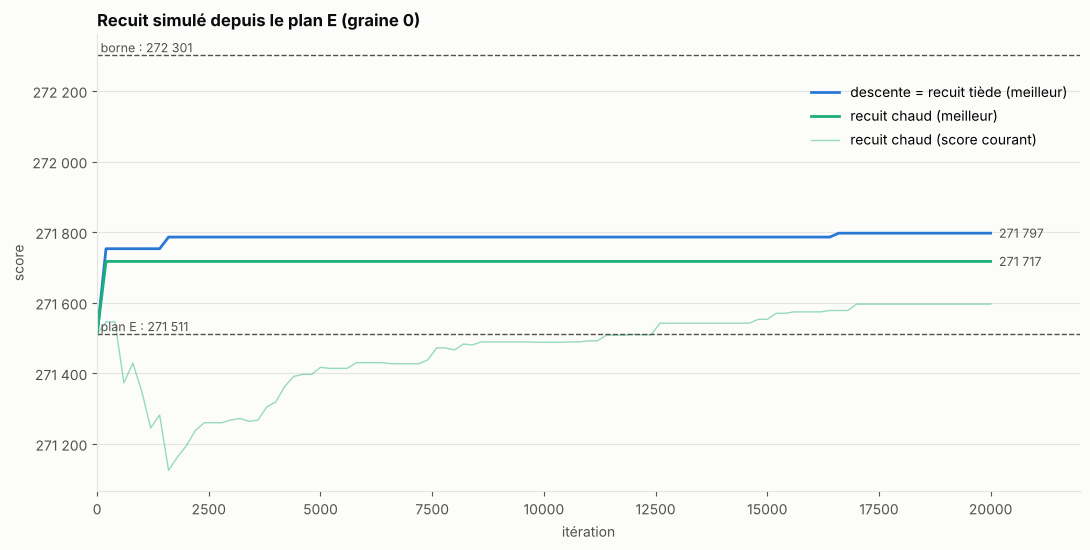

In [7]:
SERIES_COLOR = {"descente": "#2a78d6", "recuit tiède": "#eb6834", "recuit chaud": "#1baf7a"}   # ordre fixe
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e5e4e1", "#fcfcfb"

fig, ax = plt.subplots(figsize=(11, 5.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
# Deux réglages qui donnent exactement la même courbe sont tracés une seule fois, avec un nom commun
curves = {}
for name in SETTINGS:
    key = tuple(histories[(name, 0)]["meilleur"])
    curves.setdefault(key, []).append(name)
for names in curves.values():
    h = histories[(names[0], 0)]
    label = " = ".join(names)
    ax.plot(h["itération"], h["meilleur"], lw=2, color=SERIES_COLOR[names[0]], label=f"{label} (meilleur)")
    ax.annotate(f"{h['meilleur'].iloc[-1]:,}".replace(",", " "), (h["itération"].iloc[-1], h["meilleur"].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=INK_2)
h = histories[("recuit chaud", 0)]                       # le score courant montre l'exploration à haute température
ax.plot(h["itération"], h["score_courant"], lw=1, color=SERIES_COLOR["recuit chaud"], alpha=0.45,
        label="recuit chaud (score courant)")
for y, label in [(score_e, "plan E"), (bound, "borne")]:
    ax.axhline(y, color=INK_2, lw=1, ls="--")
    ax.text(0, y, f" {label} : {y:,.0f}".replace(",", " "), va="bottom", fontsize=9, color=INK_2)
ax.set_xlabel("itération", color=INK_2); ax.set_ylabel("score", color=INK_2)
ax.set_title("Recuit simulé depuis le plan E (graine 0)", loc="left", fontweight="bold", color=INK)
ax.grid(axis="y", color=GRID); ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color(GRID); ax.tick_params(colors=INK_2)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ")))
ax.set_xlim(0, N_ITER * 1.1)
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1, 0.92))
fig.tight_layout(); plt.show()

**Lecture**
- La descente et le recuit tiède donnent **exactement les mêmes résultats**, pour les trois graines. Près du plan E, les pertes proposées valent toujours plusieurs dizaines de points. À $T \le 2$, leur probabilité d'acceptation $e^{\Delta/T}$ est quasi nulle : le recuit tiède se comporte donc comme une descente.
- Le recuit chaud fait **moins bien** pour les trois graines. Le trait fin montre pourquoi : au début, il accepte des pertes et s'éloigne du plan E. Ensuite, il passe le reste du temps à remonter, sans jamais retrouver une solution aussi bonne.
- Les gains arrivent par paliers, avec de longues périodes sans progrès : c'est la signature d'un algorithme qui travaille près d'un optimum.
- Ce n'est pas une règle générale. Le recuit chaud est utile quand on part d'une solution médiocre, ou quand le paysage a beaucoup d'optima locaux éloignés les uns des autres. Ici, on part presque du sommet.

### Quels mouvements travaillent ?

In [8]:
_, _, _, stats = anneal(plan_e, *SETTINGS["descente"], N_ITER, seed=0)
stats["taux_acceptation"] = (stats.acceptés / stats.essais).map("{:.1%}".format)
stats

,essais,acceptés,gains,taux_acceptation
upgrade,3000,4,4,0.1%
exchange,7015,4,4,0.1%
swap_in,7019,0,0,0.0%
ruin,2966,35,0,1.2%


**Lecture**
- Plus de 99 % des mouvements sont refusés. C'est normal près d'un optimum, où presque toute modification fait perdre des points.
- **Tous les gains viennent des données libres** (`upgrade` et `exchange`) : mieux répartir les données libres fait passer des modèles à pleine valeur. Huit améliorations seulement suffisent à gagner près de 300 points.
- `swap_in` (énergie) n'est jamais accepté : le plan E a déjà choisi les bons modèles. L'énergie était bien arbitrée, la répartition des données libres un peu moins.
- `ruin` est accepté sans jamais rien gagner. Ce sont des mouvements **neutres** ($\Delta = 0$) : le recuit remplace des modèles par d'autres de même valeur. Ces déplacements « à plat » ne servent pas à rien : ils réorganisent les données et rendent possibles de nouveaux `upgrade`.

## 8. Un essai long avec le meilleur réglage

In [9]:
best_setting = runs.groupby("réglage", sort=False).score.mean().idxmax()
T0, T1 = SETTINGS[best_setting]
t0 = time.time()
plan_f, score_f, hist_f, _ = anneal(plan_e, T0, T1, 100_000, seed=1)
print(f"réglage : {best_setting} | 100 000 itérations | {time.time() - t0:.0f} s")
print(f"plan F : {score_f:,} (+{score_f - score_e} points, {(score_f - score_e) / (bound - score_e):.0%} de l'écart comblé)")


réglage : descente | 100 000 itérations | 22 s
plan F : 271,874 (+363 points, 46% de l'écart comblé)


## 9. Comparaison et vérification

In [10]:
summary = pd.DataFrame({
    "score": [score_e, score_f, round(bound)],
    "part_de_la_borne": [f"{score_e / bound:.2%}", f"{score_f / bound:.2%}", "100 %"],
}, index=["plan E (glouton + PL)", "plan F (E + recuit)", "borne sans modèles impossibles"])
display(summary)

score, valid, message = getSolutionScore(json.dumps(plan_f), DATASET_TXT, show_details=True)
print("score officiel =", score, "| valide =", valid, message)

,score,part_de_la_borne
plan E (glouton + PL),271511,99.71%
plan F (E + recuit),271874,99.84%
borne sans modèles impossibles,272301,100 %



Total value: 271874
Energy used: 209399476339804 / 209400189201537 (100.00%)
Number of used models: 876 / 3000 (29.20%)
  Number of devalued models: 332 (37.90%)
  Number of models used as data source: 0 (0.00%)
Number of used datasets: 5189 / 10000 (51.89%)
score officiel = 271874 | valide = True 


## 10. Écrire le fichier de solution
On ne remplace la solution principale que si le recuit l'a améliorée, après validation officielle.

In [11]:
out_dir = ROOT_DIR / "solutions"
(out_dir / "2_medium_recuit.json").write_text(json.dumps(plan_f))
if valid and score > score_e:
    (out_dir / "2_medium_main.json").write_text(json.dumps(plan_f))
    print(f"2_medium_main.json mis à jour : {score_e} -> {score}")
else:
    print("2_medium_main.json inchangé")

2_medium_main.json mis à jour : 271511 -> 271874


## À retenir
1. **Un recuit ne s'écrit pas sans un bon état.** Le plus gros du travail, c'est la classe `State` : mise à jour du score sans tout recalculer, et annulation exacte d'un mouvement refusé.
2. **Les mouvements comptent plus que la température.** Un mouvement doit agir sur une ressource rare. Ici, on en a écrit pour l'énergie et pour les données libres, en réutilisant ce que le notebook 09 avait appris.
3. **Partir d'une très bonne solution change la donne.** Depuis le plan E, la descente pure fait aussi bien que le recuit : l'exploration à haute température n'a rien à découvrir et abîme la solution.
4. **Le recuit comble une partie de l'écart, pas tout.** Ici, il gagne 363 points en une vingtaine de secondes, soit près de la moitié de l'écart. La borne dit qu'il reste au plus quelques centaines de points, peut-être moins, car elle n'est pas forcément atteignable.
5. **Toujours fixer la graine et faire plusieurs essais.** Un algorithme aléatoire se compare sur plusieurs graines, jamais sur un seul tirage.